<a href="https://colab.research.google.com/github/JUAN-VILLOTA/har-smartphones-ml-grupo11/blob/main/01_descripcion_y_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Human Activity Recognition Using Smartphones — Grupo 11
## Parte 1. Descripción del problema y análisis exploratorio

**Integrantes:** Juan David Villota Córdoba y Sammir Alejandro Bolaños Luna  
**Curso:** Introducción al Aprendizaje Automático — Universidad de Antioquia, 2026-2  
**Base de datos:** [Human Activity Recognition Using Smartphones (UCI)](https://doi.org/10.24432/C54S4K)


## 1. Entender el problema

Treinta voluntarios llevaron un **Samsung Galaxy S II en la cintura** mientras realizaban seis actividades. El teléfono registró señales del acelerómetro y del giroscopio. Las sesiones se grabaron en video para asignar manualmente las etiquetas.

## 2. Preparar las herramientas

Importamos las bibliotecas que usaremos para leer, organizar y visualizar los datos. En esta etapa todavía no entrenamos modelos.

## 3. Descargar y abrir la base

Descargamos la versión publicada en UCI y abrimos el ZIP en memoria.

In [1]:
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
with urllib.request.urlopen(URL) as r:
    z = zipfile.ZipFile(io.BytesIO(r.read()))

# El zip de UCI puede traer otro zip adentro ("UCI HAR Dataset.zip")
internos = [n for n in z.namelist() if n.endswith(".zip")]
if internos:
    z = zipfile.ZipFile(io.BytesIO(z.read(internos[0])))

## 4. Crear una función de lectura

Los archivos de UCI contienen valores separados por espacios y no incluyen encabezados. La función `leer` permite cargar archivos por el final de su ruta, evitando repetir instrucciones.

In [2]:
def leer(sufijo, **kw):
    ruta = [n for n in z.namelist() if n.endswith(sufijo) and "Inertial" not in n][0]
    return pd.read_csv(z.open(ruta), sep=r"\s+", header=None, **kw)

features = leer("features.txt")[1].tolist()
etiquetas = leer("activity_labels.txt").set_index(0)[1].to_dict()
print("Número de características:", len(features))
print("Nombres de características repetidos:", len(features) - len(set(features)))
print("Actividades:", etiquetas)

Número de características: 561
Nombres de características repetidos: 84
Actividades: {1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS', 4: 'SITTING', 5: 'STANDING', 6: 'LAYING'}


In [3]:
features = leer("features.txt")[1].tolist()
etiquetas = leer("activity_labels.txt").set_index(0)[1].to_dict()

print("Número de características:", len(features))
print("Nombres de características repetidos:", len(features) - len(set(features)))
print("Actividades:")
for codigo, actividad in etiquetas.items():
    print(f"  {codigo}: {actividad}")

Número de características: 561
Nombres de características repetidos: 84
Actividades:
  1: WALKING
  2: WALKING_UPSTAIRS
  3: WALKING_DOWNSTAIRS
  4: SITTING
  5: STANDING
  6: LAYING


Algunos nombres de características están repetidos en el archivo original. Para evitar columnas ambiguas, añadiremos un sufijo solo a las repeticiones; no eliminamos ninguna característica.

In [4]:
vistos = {}
nombres = []
for nombre in features:
    vistos[nombre] = vistos.get(nombre, 0) + 1
    nombres.append(nombre if vistos[nombre] == 1 else f"{nombre}_{vistos[nombre]}")

print("Columnas listas:", len(nombres))
print("¿Todos los nombres son únicos?", len(nombres) == len(set(nombres)))

Columnas listas: 561
¿Todos los nombres son únicos? True


## 6. Cargar entrenamiento y prueba

UCI proporciona una partición oficial de **7.352 ventanas para entrenamiento** y **2.947 para prueba**. También conserva el identificador del voluntario.

In [5]:
partes = {}
for conjunto in ["train", "test"]:
    X = leer(f"X_{conjunto}.txt")
    X.columns = nombres
    X["actividad"] = leer(f"y_{conjunto}.txt")[0].map(etiquetas)
    X["sujeto"] = leer(f"subject_{conjunto}.txt")[0]
    X["conjunto"] = conjunto
    partes[conjunto] = X

print("Entrenamiento:", len(partes["train"]))
print("Prueba:", len(partes["test"]))

Entrenamiento: 7352
Prueba: 2947


### Primera mirada a las observaciones

Cada fila representa una ventana de señales, no una lectura individual del sensor. Las 561 características describen la ventana; `actividad` es la etiqueta que queremos predecir. `sujeto` y `conjunto` son metadatos útiles para el análisis, no características predictoras.

In [6]:
df = pd.concat(partes.values(), ignore_index=True)
print("Dimensiones totales (filas, columnas):", df.shape)
display(df[nombres[:6] + ["actividad", "sujeto", "conjunto"]].head())

Dimensiones totales (filas, columnas): (10299, 564)


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,actividad,sujeto,conjunto
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,STANDING,1,train
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,STANDING,1,train
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,STANDING,1,train
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,STANDING,1,train
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,STANDING,1,train


## 7. Revisar la calidad de los datos

Antes de modelar, verificamos valores faltantes, tipos de datos, rango de valores y filas duplicadas. Esto permite justificar si se requiere limpieza o imputación.

In [8]:
X_all = df[nombres]
print("Valores faltantes (NaN):", int(X_all.isna().sum().sum()))
print("Tipos de datos:", X_all.dtypes.value_counts().to_dict())
print("Mínimo global:", X_all.min().min(), "| Máximo global:", X_all.max().max())
print("Filas duplicadas:", int(X_all.duplicated().sum()))

Valores faltantes (NaN): 0
Tipos de datos: {dtype('float64'): 561}
Mínimo global: -1.0 | Máximo global: 1.0
Filas duplicadas: 0


**Cómo interpretar el resultado:** si el conteo de valores faltantes es cero, no necesitamos imputación para estas características. Más adelante, cualquier transformación como la estandarización deberá ajustarse solo con los datos de entrenamiento de cada partición.

## 8. Entender la distribución de las actividades

Contamos las ventanas de cada actividad separando entrenamiento y prueba. La tabla permite identificar si alguna clase está poco representada. Aunque las clases estén relativamente equilibradas, reportaremos métricas por clase y F1 macro para no ocultar errores específicos.

In [9]:
orden = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
tabla = pd.crosstab(df["actividad"], df["conjunto"]).reindex(orden)[["train", "test"]]
tabla["total"] = tabla.sum(axis=1)
tabla["%"] = (100 * tabla["total"] / tabla["total"].sum()).round(1)
tabla

conjunto,train,test,total,%
actividad,,,,
WALKING,1226,496,1722,16.7
WALKING_UPSTAIRS,1073,471,1544,15.0
WALKING_DOWNSTAIRS,986,420,1406,13.7
SITTING,1286,491,1777,17.3
STANDING,1374,532,1906,18.5
LAYING,1407,537,1944,18.9


## 9. Visualización exploratoria

La primera gráfica muestra cuántas ventanas hay por actividad. La segunda proyecta las características de entrenamiento en dos componentes principales (PCA) para observar patrones y posibles solapamientos entre clases.

**Importante:** esta PCA es exploratoria, no la evaluación formal de reducción de dimensión. En los experimentos posteriores, el escalador y la PCA deberán ajustarse dentro de cada partición de entrenamiento para evitar fuga de información.

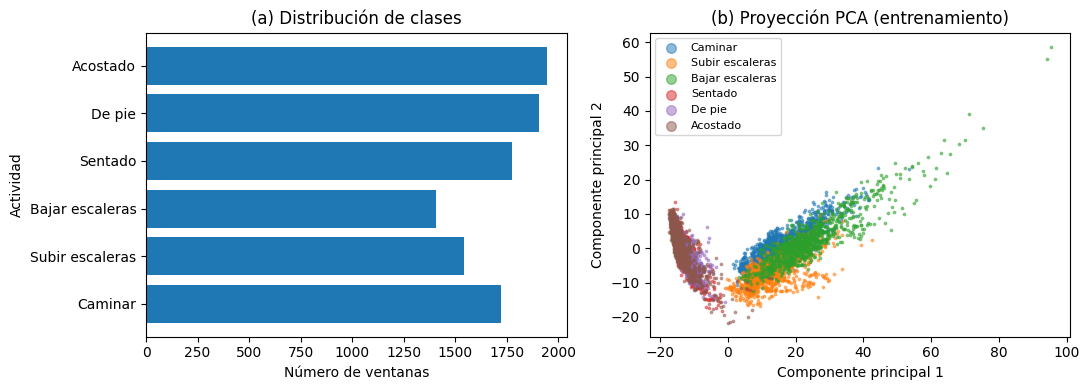

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

tr = partes["train"]
Z = PCA(n_components=2, random_state=0).fit_transform(StandardScaler().fit_transform(tr[nombres]))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh([nombres_es[a] for a in orden], tabla["total"].values)
ax[0].set_xlabel("Número de ventanas")
ax[0].set_ylabel("Actividad")
ax[0].set_title("(a) Distribución de clases")
for act in orden:
    m = tr["actividad"].values == act
    ax[1].scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.5, label=nombres_es[act])
ax[1].set_xlabel("Componente principal 1")
ax[1].set_ylabel("Componente principal 2")
ax[1].set_title("(b) Proyección PCA (entrenamiento)")
ax[1].legend(markerscale=4, fontsize=8)
fig.tight_layout()
fig.savefig("fig_eda.png", dpi=200)
plt.show()

**Nota técnica:** la PCA de esta figura se ajusta únicamente con el conjunto de entrenamiento reunido para esta exploración. La evaluación formal de reducción de dimensión se realizará más adelante con una metodología de validación adecuada.